# Kang parent-paper replication

**Question:** How closely can the published experimental setup and results be
reproduced using the current data?

[Kang et al.](https://doi.org/10.1177/23259671261477532) ·
[Protocol](../../docs/kang_replication_methods.md) ·
[Configuration](../../config/kang_replication.yaml)

This stage uses broad shoulder/elbow IL outcomes, 2017–2025 pitcher-games,
season-role strata, random-game train/test splitting, R XGBoost and ROC-AUC.
It includes the published GAM slope structure and prior-injury sensitivity.
It introduces no UCL adjudication, chronological validation, warning metrics,
new predictor concepts or alternative injury model. Unknown implementation
details are disclosed approximations, not claims of exact replication.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/kang_replication.yaml').exists())
R=ROOT/'reports/kang_replication'; T=R/'tables'
display(pd.Series(json.loads((R/'verification.json').read_text())))
print((R/'software.txt').read_text())

database_read_only                                                 True
database_unchanged                                                 True
cohorts                                                               4
completed_tasks       {'elbow_starter': 'complete', 'elbow_reliever'...
study_years                                                [2017, 2025]
primary_metric                                                  ROC-AUC
no_ucl_endpoint                                                    True
dtype: object

R version 4.5.1 (2025-06-13) 
xgboost 1.7.11.1 
mgcv 1.9.3 
jsonlite 2.0.0 



## Cohort and source differences

At least five outings per season; no more than 10% games missing required
Appendix A1 inputs. Season-majority role with innings tie-breaking. First
shoulder/elbow placement each season; only pre-placement case games.

The paper's Methods allow controls with other IL injuries; Results describe
controls without any IL. The Methods interpretation is primary here. The
alternative is counted, not chosen based on scores. Existing UCL episode-QA
filters and primary-position exclusions are not added. Unknown-diagnosis
control seasons remain source-uncertain, not certified healthy.

In [2]:
display(pd.read_csv(T/'cohort_flow.csv'))
display(pd.read_csv(T/'cohort_counts.csv'))
display(pd.read_csv(T/'event_qa_descriptive.csv'))
display(pd.read_csv(T/'exclusions_by_season.csv'))

,stage,games,pitcher_seasons,unique_pitchers
0,raw_pitching,175708,7491,2298
1,five_appearances,172463,5981,1800
2,missingness_and_role,172044,5943,1794


,endpoint,role,control_definition,games,unique_pitchers,pitcher_seasons,events,control_seasons,unknown_diagnosis_control_seasons
0,elbow,starter,no_shoulder_elbow_il,34477,620,1665,123,1542,127
1,elbow,starter,no_any_il,21884,538,1068,123,945,0
2,elbow,reliever,no_shoulder_elbow_il,119590,1418,3669,233,3436,194
3,elbow,reliever,no_any_il,88929,1314,2781,233,2548,0
4,shoulder,starter,no_shoulder_elbow_il,35384,627,1735,193,1542,127
5,shoulder,starter,no_any_il,22791,550,1138,193,945,0
6,shoulder,reliever,no_shoulder_elbow_il,120704,1421,3737,301,3436,194
7,shoulder,reliever,no_any_il,90043,1315,2849,301,2548,0


,endpoint,first_placements,events_contributing_games,overlap_flags,timing_flags,multiple_anatomy_flags
0,elbow,558,356,43,10,3
1,shoulder,657,494,24,14,3


,season,pitcher_seasons,eligible,excluded_fewer_five,excluded_missing
0,2017,755,645,107,4
1,2018,799,649,139,13
2,2019,831,684,138,16
3,2020,735,539,192,6
4,2021,909,710,198,2
5,2022,871,682,187,2
6,2023,863,678,183,2
7,2024,855,666,186,5
8,2025,873,690,180,5


## Published predictors

Use the 22 Appendix A1 inputs. Longitudinal release Y is tabulated elsewhere in
the article but absent from that list; extension is included and Y remains
crosswalk-only. The source has all required concepts. Match quality refers to
variable definition, not identical observations or preprocessing to the authors.

In [3]:
display(pd.read_csv(T/'feature_crosswalk.csv')[['kang_concept','feature','match_quality','used_in_model','notes']])

,kang_concept,feature,match_quality,used_in_model,notes
0,Age,age_at_appearance,exact,True,Same concept; source cleaning and original aut...
1,Total pitches,total_pitches,exact,True,Same concept; source cleaning and original aut...
2,Innings pitched,innings_pitched,exact,True,Same concept; source cleaning and original aut...
3,Batters faced,batters_faced,exact,True,Same concept; source cleaning and original aut...
4,Mean velocity,avg_velocity,exact,True,Same concept; source cleaning and original aut...
5,Maximum velocity,max_velocity,exact,True,Same concept; source cleaning and original aut...
6,Velocity SD (all pitch types),kang_velocity_sd,close proxy,True,Same concept; source cleaning and original aut...
7,Mean spin rate,spin_avg,exact,True,Same concept; source cleaning and original aut...
8,Maximum spin rate,kang_spin_max,close proxy,True,Same concept; source cleaning and original aut...
9,Spin rate SD,kang_spin_sd,close proxy,True,Same concept; source cleaning and original aut...


## Candidate windows and inferred slope bands

Training-only five-fold AUC over integer windows 7–49 days; the publication
does not specify the candidate increment. `mgcv` smooths AUC, and the declining
derivative is compared with 25–35% of its maximum. Green shading shows actual
qualifying segments; orange shows published intervals. The dotted line marks
the rounded envelope midpoint used for the final model, an unpublished-detail
approximation. Disconnected green regions do not identify a unique optimal
window. Bands are not confidence intervals; no maximum-AUC fallback is used.

,task,lower,upper,selected,segments,maximum_slope,status,selected_day_in_band
0,elbow_starter,26.88,29.39,28,1,0.0146,inferred_with_disclosed_gam_settings,True
1,elbow_reliever,23.69,26.33,25,1,0.0128,inferred_with_disclosed_gam_settings,True
2,shoulder_starter,12.69,32.93,23,4,0.0193,inferred_with_disclosed_gam_settings,False
3,shoulder_reliever,27.26,34.46,31,1,0.0119,inferred_with_disclosed_gam_settings,True


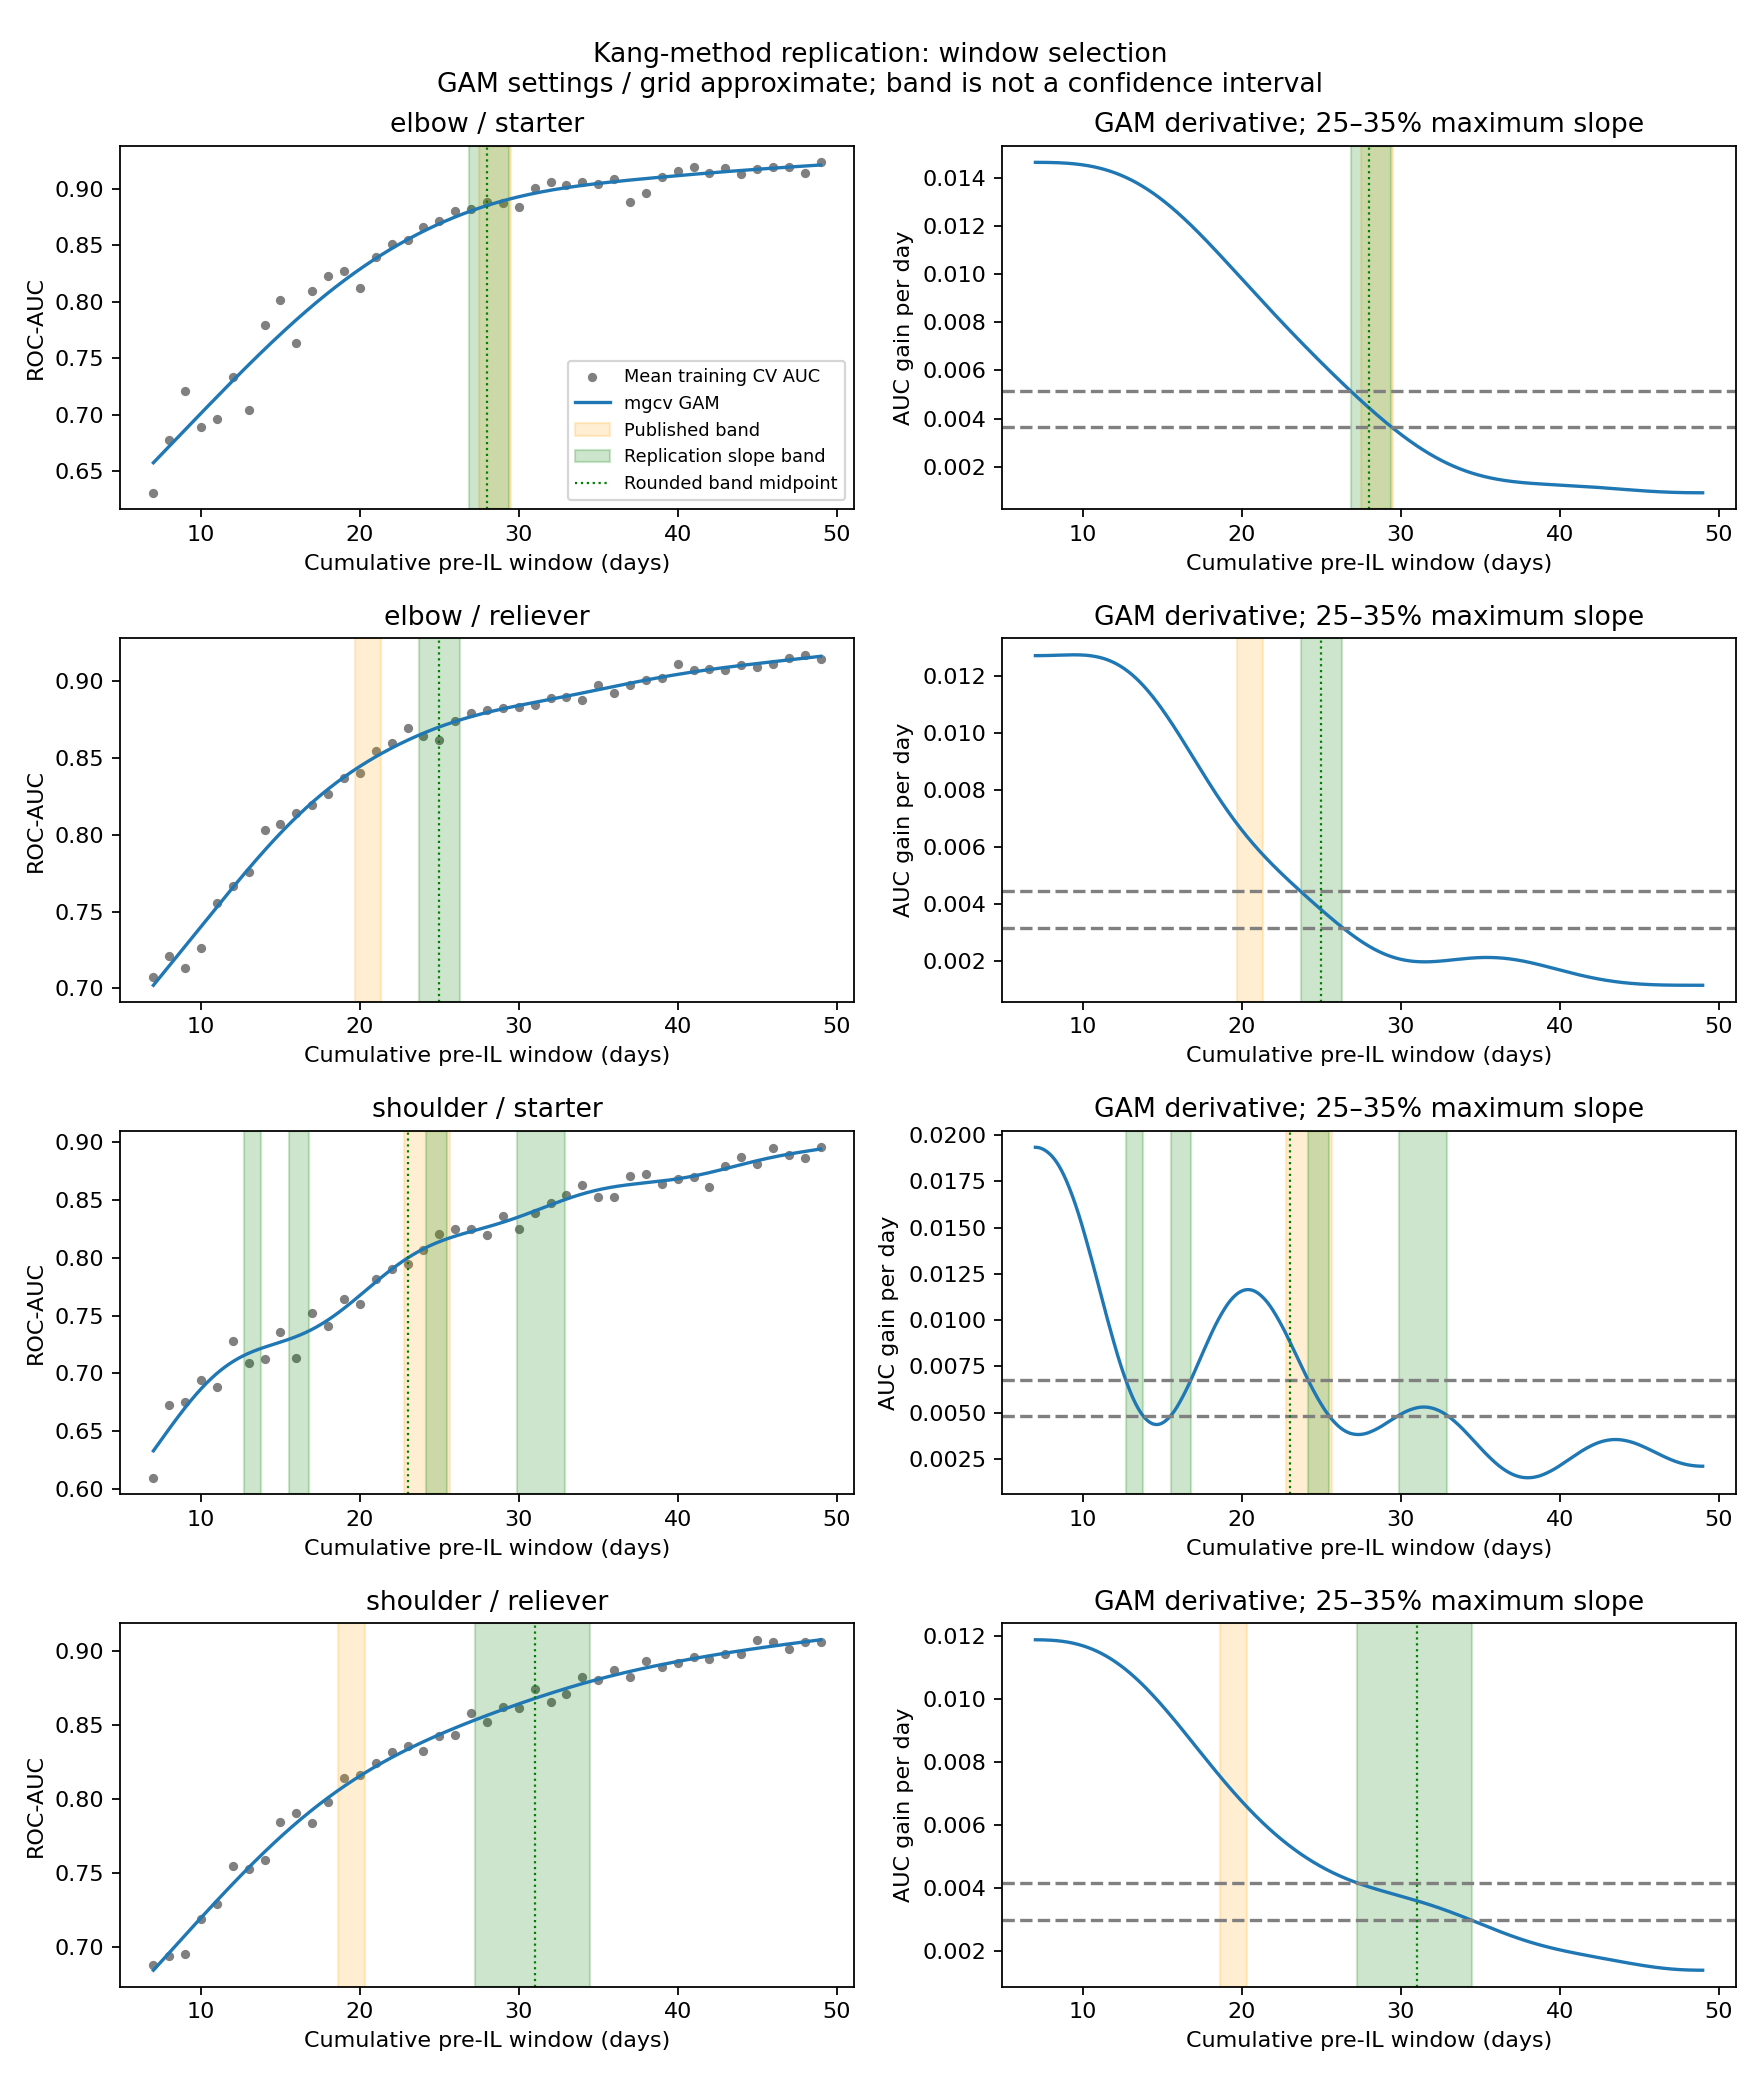

In [4]:
display(pd.read_csv(T/'optimal_windows.csv'))
display(Image(filename=str(R/'figures/01_window_and_slope.png')))

## ROC-AUC and published comparison

50 repetitions of stratified five-fold fits on training subsets support gain/
consistency selection, followed by within-domain Pearson pruning at |r| > .7.
The final XGBoost specification is untuned because author tuning settings are
unavailable. ROC-AUC intervals resample held-out pitcher-seasons 500 times.
The same pitchers can appear in both train and test, as in the paper.

,window,lower,upper,train_games,test_games,positive_test_games,test_events,features,roc_auc,ci_low,ci_high,valid_bootstraps,shared_pitchers,task,published_auc,band_segments,selected_day_in_band
0,28,26.88,29.39,23098,11379,167,100,18,0.9245,0.9048,0.9442,500,614,elbow_starter,0.868,1,True
1,25,23.69,26.33,80124,39466,544,208,18,0.9097,0.8910,0.9256,500,1403,elbow_reliever,0.815,1,True
2,23,12.69,32.93,23706,11678,229,141,18,0.8555,0.8242,0.8828,500,617,shoulder_starter,0.815,4,False
3,31,27.26,34.46,80871,39833,844,277,18,0.8961,0.8834,0.9092,500,1406,shoulder_reliever,0.797,1,True


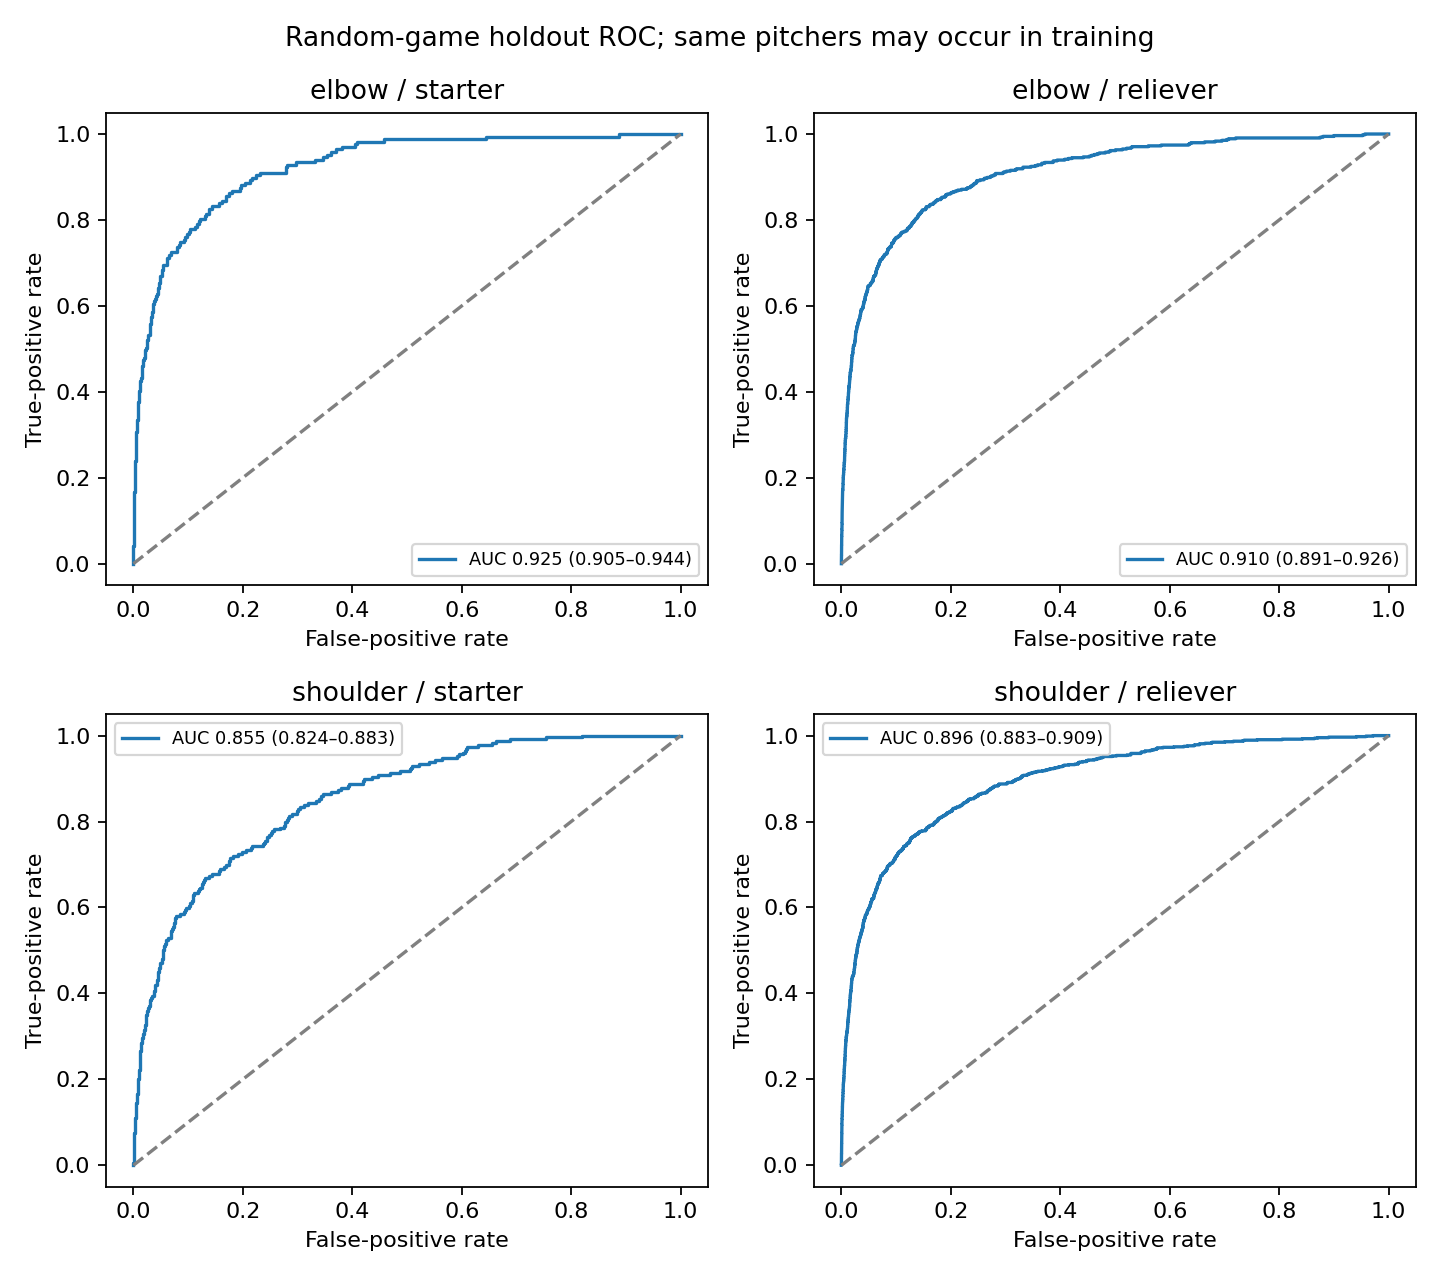

,task,quantity,kang,replication,explanation,numeric_difference
0,elbow_starter,pitcher-games,34285,34477,Official-source IL coding and Methods control ...,192.000000
1,elbow_starter,pitcher-seasons,1114,1665,Official-source IL coding and Methods control ...,551.000000
2,elbow_starter,unique pitchers within role,553,620,Official-source IL coding and Methods control ...,67.000000
3,elbow_starter,injury events with pre-IL games,146,123,Official-source IL coding and Methods control ...,-23.000000
4,elbow_starter,slope-band window days,27.5–29.5,26.88–29.39,Daily candidate grid and mgcv defaults are dis...,NaN
5,elbow_starter,test ROC-AUC,0.868,0.924505608832282,"Different source cohort, unknown original hype...",0.056506
6,elbow_starter,top five mean total-Gain features,"release Z, absolute X, extension, slider fract...","age_at_appearance, release_z_avg, kang_release...",Training bootstrap Gain; correlated alternativ...,NaN
7,elbow_reliever,pitcher-games,81975,119590,Official-source IL coding and Methods control ...,37615.000000
8,elbow_reliever,pitcher-seasons,2856,3669,Official-source IL coding and Methods control ...,813.000000
9,elbow_reliever,unique pitchers within role,1101,1418,Official-source IL coding and Methods control ...,317.000000


In [5]:
display(pd.read_csv(T/'roc_auc_results.csv').round(4))
display(Image(filename=str(R/'figures/03_roc_curves.png')))
display(pd.read_csv(T/'published_comparison.csv'))

## Feature importance and prior-injury sensitivity

Importance is R XGBoost's normalized total split Gain averaged over 500 training
pitcher-season bootstrap refits. Correlated features can exchange importance;
these rankings are not physiological explanations. The sensitivity adds only
the paper's corresponding-region IL history from previous study seasons.

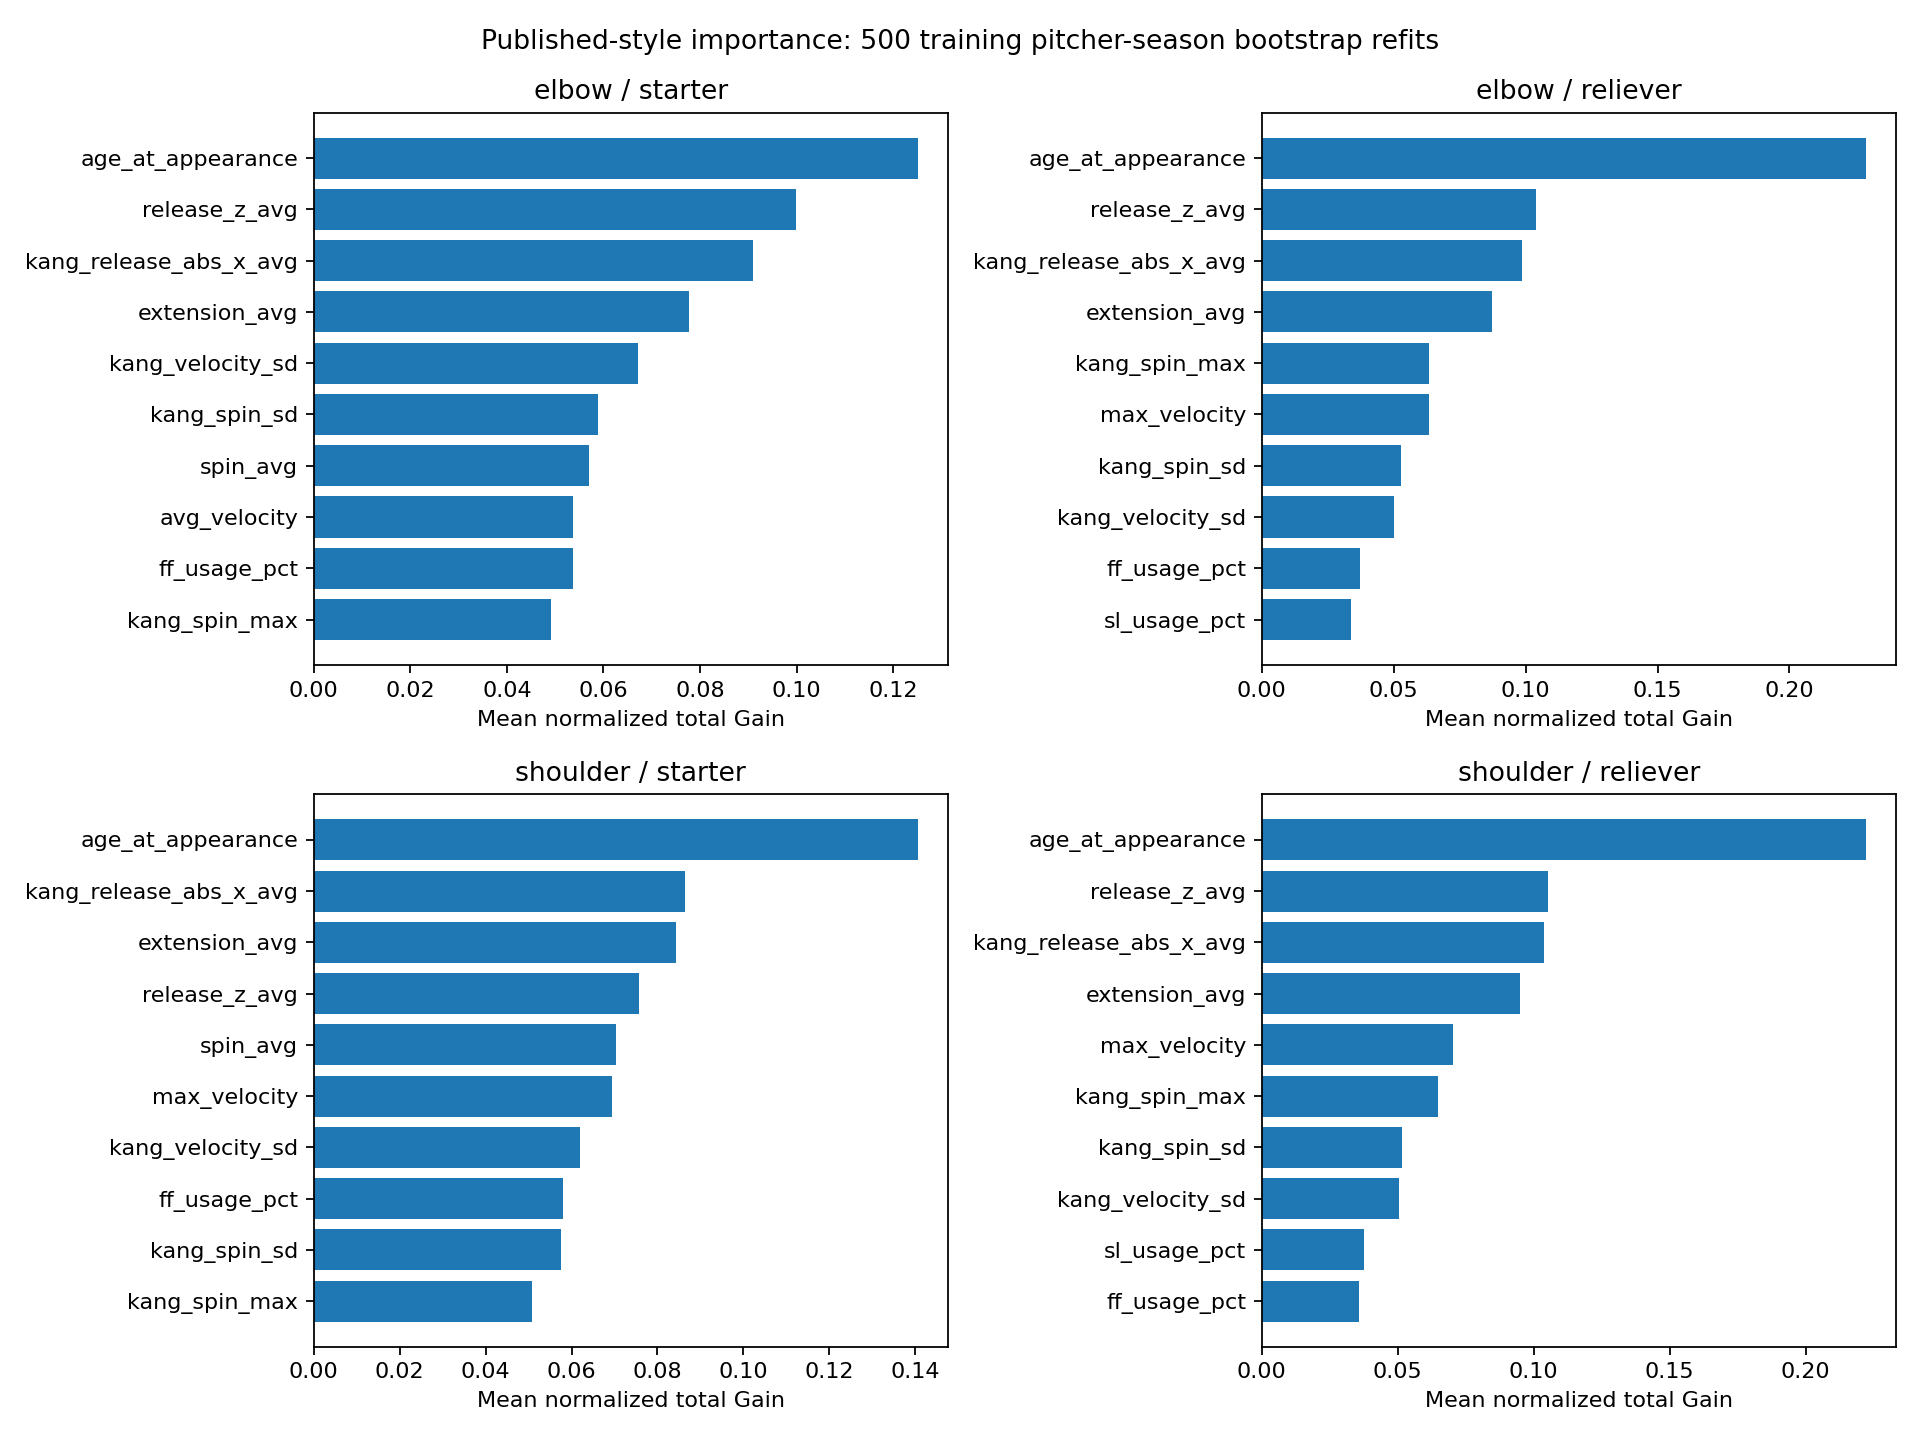

,feature,mean_gain,gain_sd,valid_refits,task,domain
0,age_at_appearance,0.125115,0.018843,500,elbow_starter,context
1,release_z_avg,0.099895,0.015028,500,elbow_starter,release
2,kang_release_abs_x_avg,0.090925,0.016439,500,elbow_starter,release
3,extension_avg,0.077801,0.014785,500,elbow_starter,release
4,kang_velocity_sd,0.067246,0.013396,500,elbow_starter,velocity
18,age_at_appearance,0.228941,0.016448,500,elbow_reliever,context
19,release_z_avg,0.103948,0.010375,500,elbow_reliever,release
20,kang_release_abs_x_avg,0.098578,0.010085,500,elbow_reliever,release
21,extension_avg,0.087085,0.009018,500,elbow_reliever,release
22,kang_spin_max,0.063528,0.008376,500,elbow_reliever,spin


,roc_auc,ci_low,ci_high,delta_auc,task,published_auc
0,0.907114,0.883937,0.930083,-0.017392,elbow_starter,0.872
1,0.915547,0.901143,0.929377,0.005831,elbow_reliever,0.829
2,0.850058,0.819477,0.878254,-0.005410,shoulder_starter,0.858
3,0.908237,0.895099,0.921069,0.012152,shoulder_reliever,0.835


In [6]:
display(Image(filename=str(R/'figures/02_feature_importance.png')))
display(pd.read_csv(T/'feature_importance.csv').groupby('task',sort=False).head(5))
display(pd.read_csv(T/'prior_injury_sensitivity.csv'))

## Fidelity and interpretation

The source differences and unknown author settings prevent exact numerical
replication. In particular, control wording, release-Y/extension naming, earlier
case-game handling, candidate increments, tuning/selection cutoffs and GAM
settings require qualification. The article's feature-specific rolling-risk
attribution is insufficiently defined for a numerical reproduction; no new
method was substituted. Read the computed report below before deciding whether
the structural benchmark is adequate for subsequent one-change comparisons.

In [7]:
display(Markdown((R/'summary.md').read_text()))

# Kang parent-paper replication

This stage reproduces the published experimental structure using existing data. It adds no UCL-specific endpoint, chronological split, new warning metric, learner comparison or project-specific predictor.

## Cohort

| endpoint   | role     | control_definition   |   games |   unique_pitchers |   pitcher_seasons |   events |   control_seasons |   unknown_diagnosis_control_seasons |
|:-----------|:---------|:---------------------|--------:|------------------:|------------------:|---------:|------------------:|------------------------------------:|
| elbow      | starter  | no_shoulder_elbow_il |   34477 |               620 |              1665 |      123 |              1542 |                                 127 |
| elbow      | reliever | no_shoulder_elbow_il |  119590 |              1418 |              3669 |      233 |              3436 |                                 194 |
| shoulder   | starter  | no_shoulder_elbow_il |   35384 |               627 |              1735 |      193 |              1542 |                                 127 |
| shoulder   | reliever | no_shoulder_elbow_il |  120704 |              1421 |              3737 |      301 |              3436 |                                 194 |

The Methods control definition is primary; counts using the conflicting Results no-IL definition are retained in `tables/cohort_counts.csv`. Events and controls are shared across repeated games; endpoint totals must not be summed as unique people.

## Window and discrimination comparison

| task              |   lower |   upper |   band_segments |   window | selected_day_in_band   |   roc_auc |   ci_low |   ci_high |   published_auc |   features |
|:------------------|--------:|--------:|----------------:|---------:|:-----------------------|----------:|---------:|----------:|----------------:|-----------:|
| elbow_starter     |   26.88 |   29.39 |               1 |       28 | True                   |     0.925 |    0.905 |     0.944 |           0.868 |         18 |
| elbow_reliever    |   23.69 |   26.33 |               1 |       25 | True                   |     0.91  |    0.891 |     0.926 |           0.815 |         18 |
| shoulder_starter  |   12.69 |   32.93 |               4 |       23 | False                  |     0.855 |    0.824 |     0.883 |           0.815 |         18 |
| shoulder_reliever |   27.26 |   34.46 |               1 |       31 | True                   |     0.896 |    0.883 |     0.909 |           0.797 |         18 |

Bands come from the published GAM derivative structure, not maximum AUC. They are not confidence intervals. The candidate increment, smoother settings and band-to-integer conversion are undisclosed in the article and explicitly approximated here.

Multiple qualifying segments mean the earliest/latest interval is an envelope containing gaps; its rounded midpoint can fall outside every qualifying segment. Such a result is not a well-identified unique optimal window, even when its midpoint resembles the published window.

- **elbow / starter:** The band overlaps the published interval; this is descriptive agreement, not an equivalence test.
- **elbow / reliever:** The qualifying band is later/longer than the published band.
- **shoulder / starter:** 4 disconnected segments; the envelope does not identify a unique window.
- **shoulder / reliever:** The qualifying band is later/longer than the published band.

## Feature importance

| task              | feature                | domain   |   mean_gain |
|:------------------|:-----------------------|:---------|------------:|
| elbow_starter     | age_at_appearance      | context  |      0.1251 |
| elbow_starter     | release_z_avg          | release  |      0.0999 |
| elbow_starter     | kang_release_abs_x_avg | release  |      0.0909 |
| elbow_starter     | extension_avg          | release  |      0.0778 |
| elbow_starter     | kang_velocity_sd       | velocity |      0.0672 |
| elbow_reliever    | age_at_appearance      | context  |      0.2289 |
| elbow_reliever    | release_z_avg          | release  |      0.1039 |
| elbow_reliever    | kang_release_abs_x_avg | release  |      0.0986 |
| elbow_reliever    | extension_avg          | release  |      0.0871 |
| elbow_reliever    | kang_spin_max          | spin     |      0.0635 |
| shoulder_starter  | age_at_appearance      | context  |      0.1406 |
| shoulder_starter  | kang_release_abs_x_avg | release  |      0.0864 |
| shoulder_starter  | extension_avg          | release  |      0.0844 |
| shoulder_starter  | release_z_avg          | release  |      0.0756 |
| shoulder_starter  | spin_avg               | spin     |      0.0703 |
| shoulder_reliever | age_at_appearance      | context  |      0.2221 |
| shoulder_reliever | release_z_avg          | release  |      0.1051 |
| shoulder_reliever | kang_release_abs_x_avg | release  |      0.1037 |
| shoulder_reliever | extension_avg          | release  |      0.0949 |
| shoulder_reliever | max_velocity           | velocity |      0.0702 |

Gain is normalized total split gain averaged over training bootstrap refits; it does not identify physiological mechanisms.

## Fidelity and unresolved details

Matched: years, game grain, broad injury framing, role strata, random 67/33 games with pitcher overlap, XGBoost, inverse-frequency weighting, 50 repeated five-fold selection fits, domain Pearson threshold 0.7, ROC-AUC and 500 pitcher-season confidence resamples. The same GAM slope-band structure and prior-region injury sensitivity were implemented.

Approximate/unavailable: author cohort records, conflicting control wording, exact feature list (Y versus extension), outside-window case handling, exact random seed/grid, selection cutoffs/subset size, tuning procedure, hyperparameters, software versions, smoother settings and final window conversion. The published feature-specific rolling-risk attribution lacks enough detail for numerical replication and was not replaced with a new method.

This is a reproducible **qualified structural benchmark**, not an exact numerical replication or evidence of deployment performance. Do not change settings to force agreement. Author code/data would be needed to remove the documented ambiguities.

See [protocol](../../docs/kang_replication_methods.md), [config](../../config/kang_replication.yaml), and [direct comparison](tables/published_comparison.csv). Existing analyses and the central database remain unchanged.
